<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab5/lab5_deep_learning_llms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 5 – Deep learning and LLMs for NLP

**Objectives**
- Train small recurrent networks (RNN, LSTM, GRU) with PyTorch on three NLP tasks
- Use a pre-trained transformer for named entity recognition
- Call a large language model through an API and compare it with the models trained in the lab

| Part | Model | Task | Data |
|------|-------|------|------|
| A | RNN | Character-level language model | Tiny Shakespeare |
| B | LSTM | Sentiment classification | IMDB reviews |
| C | GRU | News classification | AG News |
| D | Transformer (BERT) | Named entity recognition | Your own sentences |
| E | LLM (API) | Zero-shot classification, summarization, extraction | IMDB, Nike products |

A GPU is not required: the models are small and train in a few minutes on a CPU. On Google Colab, `Runtime > Change runtime type > T4 GPU` makes Parts A-C faster.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. Part E calls an LLM API. The teacher provides a temporary key in a `.env` file (valid for one day); see the beginning of Part E. Without a key, Part E is skipped and the rest of the lab is not affected.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
!pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, json, time, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} on {device}")

def local_file(name, lab="lab5"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

PyTorch 2.14.1+cpu on cpu


---
# Part A – RNN: character-level language model

**Use case:** predict the next character (autocomplete). The model reads 30 characters and predicts the 31st.

**Data:** Tiny Shakespeare (1 MB of plays), from the original repository of the dataset.

In [3]:
try:
    text = urllib.request.urlopen("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", timeout=30).read().decode("utf-8")
    print("Loaded from GitHub")
except Exception as e:
    print(f"GitHub unavailable ({type(e).__name__}), using the local copy")
    text = open(local_file("tinyshakespeare.txt"), encoding="utf-8").read()

text = text[:20000]   # first 20 000 characters: enough for a demo
print(f"{len(text)} characters\n")
print(text[:300])

Loaded from GitHub
20000 characters

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


In [4]:
chars = sorted(set(text))
vocab_size = len(chars)
char_to_idx = {c: i for i, c in enumerate(chars)}
idx_to_char = {i: c for i, c in enumerate(chars)}
print(f"Vocabulary: {vocab_size} characters")

seq_length = 30
X = torch.tensor([[char_to_idx[c] for c in text[i:i + seq_length]] for i in range(len(text) - seq_length)])
y = torch.tensor([char_to_idx[text[i + seq_length]] for i in range(len(text) - seq_length)])
print(f"{X.shape[0]} sequences of length {seq_length}")

Vocabulary: 58 characters
19970 sequences of length 30


In [5]:
class CharRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        out, _ = self.rnn(self.embedding(x))   # out: (batch, seq, hidden)
        return self.fc(out[:, -1, :])          # prediction from the last time step

rnn_model = CharRNN(vocab_size).to(device)
print(f"RNN parameters: {sum(p.numel() for p in rnn_model.parameters()):,}")

RNN parameters: 30,074


### Exercise A.1 – Training loop

Epoch 1/5 – loss 1.7717
Epoch 2/5 – loss 1.7001
Epoch 3/5 – loss 1.6660
Epoch 4/5 – loss 1.6336
Epoch 5/5 – loss 1.6142


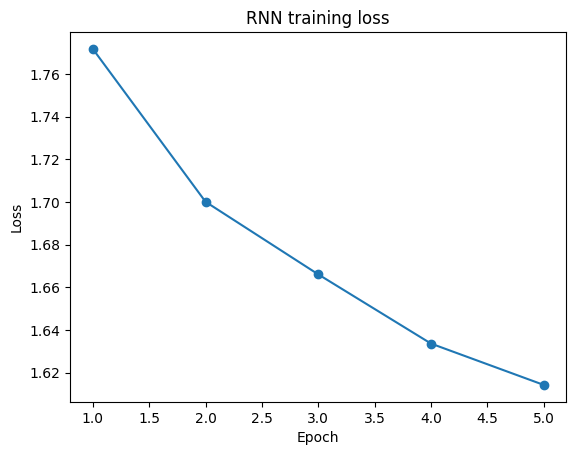

In [10]:
learning_rate = 0.005   # YOUR CODE HERE: between 0.001 and 0.01
epochs, batch_size = 5, 128
loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(rnn_model.parameters(), lr=learning_rate)

losses = []
for epoch in range(epochs):
    rnn_model.train()
    total_loss = 0.0
    for batch_X, batch_y in loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        # YOUR CODE HERE
        optimizer.zero_grad()
        output = rnn_model(batch_X)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        pass
    losses.append(total_loss / len(loader))
    print(f"Epoch {epoch + 1}/{epochs} – loss {losses[-1]:.4f}")

assert losses[-1] < losses[0] and losses[-1] > 0, "The loss should decrease over the epochs"
plt.plot(range(1, epochs + 1), losses, marker="o"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("RNN training loss"); plt.show()

In [11]:
def generate_text(model, start, length=200, temperature=0.8):
    """Sample characters one by one from the model's predictions."""
    model.eval()
    generated = list(start)
    with torch.no_grad():
        for _ in range(length):
            seq = [char_to_idx.get(c, 0) for c in generated[-seq_length:]]
            seq = [0] * (seq_length - len(seq)) + seq
            logits = model(torch.tensor([seq]).to(device))[0] / temperature
            next_idx = torch.multinomial(torch.softmax(logits, dim=0), 1).item()
            generated.append(idx_to_char[next_idx])
    return "".join(generated)

print(generate_text(rnn_model, "ROMEO: "))

ROMEO: I, these she reperat;
I, in finder,
Marcius ware now till he ware dome in rearter in you and the poare it first till Vuss this know
Which he reveled the bod is the disdend. it shome bollert you lade b


---
# Part B – LSTM: sentiment classification

**Use case:** classify movie reviews as positive or negative.

**Data:** IMDB (1 000 training reviews, 200 test reviews, first 100 tokens of each review).

In [12]:
from datasets import load_dataset

def load_imdb():
    ds = load_dataset("stanfordnlp/imdb")
    tr = pd.DataFrame(ds["train"]).sample(n=1000, random_state=42)
    te = pd.DataFrame(ds["test"]).sample(n=200, random_state=42)
    return tr, te

try:
    imdb_train, imdb_test = load_imdb(); print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local sample")
    df = pd.read_csv(local_file("imdb_sample.csv.gz"))
    imdb_train, imdb_test = df[df["split"] == "train"], df[df["split"] == "test"]
imdb_train, imdb_test = imdb_train.reset_index(drop=True), imdb_test.reset_index(drop=True)
print(f"Train: {len(imdb_train)}, test: {len(imdb_test)}")
print(imdb_train.iloc[0]["text"][:300], "-> label", imdb_train.iloc[0]["label"])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Loaded from Hugging Face
Train: 1000, test: 200
Dumb is as dumb does, in this thoroughly uninteresting, supposed black comedy. Essentially what starts out as Chris Klein trying to maintain a low profile, eventually morphs into an uninspired version of "The Three Amigos", only without any laughs. In order for black comedy to work, it must be outra -> label 0


In [13]:
MAX_LEN = 100

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

def build_vocab(texts, size=5000):
    counts = Counter(tok for t in texts for tok in tokenize(t))
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for word, _ in counts.most_common(size):
        vocab[word] = len(vocab)
    return vocab

def encode(text, vocab, max_len=MAX_LEN):
    ids = [vocab.get(t, 1) for t in tokenize(text)][:max_len]
    return ids + [0] * (max_len - len(ids))

imdb_vocab = build_vocab(imdb_train["text"])
X_train = torch.tensor([encode(t, imdb_vocab) for t in imdb_train["text"]])
y_train = torch.tensor(imdb_train["label"].values)
X_test = torch.tensor([encode(t, imdb_vocab) for t in imdb_test["text"]])
y_test = torch.tensor(imdb_test["label"].values)
print(f"Vocabulary: {len(imdb_vocab)} tokens, X_train: {tuple(X_train.shape)}")

Vocabulary: 5002 tokens, X_train: (1000, 100)


### Exercise B.1 – The LSTM classifier

In [15]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(0.3)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)   # YOUR CODE HERE: nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = self.dropout(self.embedding(x))
        # YOUR CODE HERE
        output, (hidden, cell) = self.lstm(x)   # then use the last hidden state hidden[-1]
        return self.fc(hidden[-1])

lstm_model = LSTMClassifier(len(imdb_vocab)).to(device)
print(f"LSTM parameters: {sum(p.numel() for p in lstm_model.parameters()):,}")
assert lstm_model(X_train[:4].to(device)).shape == (4, 2), "The model must return (batch, num_classes)"

LSTM parameters: 353,538


In [16]:
def train_classifier(model, X, y, epochs=3, lr=0.001, batch_size=32):
    """Generic training loop for a classifier (cross-entropy, Adam)."""
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)
    criterion, optimizer = nn.CrossEntropyLoss(), optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train(); total = 0.0
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward(); optimizer.step()
            total += loss.item()
        print(f"Epoch {epoch + 1}/{epochs} – loss {total / len(loader):.4f}")

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        preds = model(X.to(device)).argmax(dim=1).cpu()
    return (preds == y).float().mean().item()

train_classifier(lstm_model, X_train, y_train, epochs=5)
lstm_accuracy = evaluate(lstm_model, X_test, y_test)
print(f"\nLSTM test accuracy: {lstm_accuracy:.3f}")

Epoch 1/5 – loss 0.7003
Epoch 2/5 – loss 0.6834
Epoch 3/5 – loss 0.6687
Epoch 4/5 – loss 0.6571
Epoch 5/5 – loss 0.6355

LSTM test accuracy: 0.535


---
# Part C – GRU: news classification

**Use case:** classify news articles into World / Sports / Business / Sci-Tech. The GRU has fewer gates than the LSTM, hence fewer parameters.

In [17]:
def load_ag():
    ds = load_dataset("fancyzhx/ag_news")
    return (pd.DataFrame(ds["train"]).sample(n=2000, random_state=42), pd.DataFrame(ds["test"]).sample(n=500, random_state=42))

try:
    ag_train, ag_test = load_ag(); print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local sample")
    df = pd.read_csv(local_file("ag_news_sample.csv.gz"))
    ag_train, ag_test = df[df["split"] == "train"], df[df["split"] == "test"]
ag_labels = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}

ag_vocab = build_vocab(ag_train["text"])
X_ag_train = torch.tensor([encode(t, ag_vocab, 50) for t in ag_train["text"]])
y_ag_train = torch.tensor(ag_train["label"].values)
X_ag_test = torch.tensor([encode(t, ag_vocab, 50) for t in ag_test["text"]])
y_ag_test = torch.tensor(ag_test["label"].values)
print(f"Train: {tuple(X_ag_train.shape)}, test: {tuple(X_ag_test.shape)}")

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Loaded from Hugging Face
Train: (2000, 50), test: (500, 50)


### Exercise C.1 – The GRU classifier

In [19]:
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)   # YOUR CODE HERE: nn.GRU(...)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # YOUR CODE HERE (the GRU returns (output, hidden): no cell state)
        x = self.embedding(x)
        output, hidden = self.gru(x)
        return self.fc(hidden[-1])

gru_model = GRUClassifier(len(ag_vocab)).to(device)
print(f"GRU parameters: {sum(p.numel() for p in gru_model.parameters()):,}")
assert gru_model(X_ag_train[:4].to(device)).shape == (4, 4)

GRU parameters: 345,348


### Exercise C.2 – Train and evaluate the GRU

In [21]:
# YOUR CODE HERE: reuse train_classifier (5-10 epochs) and evaluate
train_classifier(gru_model, X_ag_train, y_ag_train, epochs=8)
gru_accuracy = evaluate(gru_model, X_ag_test, y_ag_test)
print(f"\nGRU test accuracy: {gru_accuracy:.3f}")
assert gru_accuracy > 0.5, "A trained GRU should beat 50% on 4 classes"

# Compare the three architectures on the same (vocabulary, embedding, hidden) sizes
for name, cls in [("RNN", nn.RNN), ("LSTM", nn.LSTM), ("GRU", nn.GRU)]:
    layer = cls(64, 64, batch_first=True)
    print(f"{name:5}: {sum(p.numel() for p in layer.parameters()):,} parameters in the recurrent layer")

Epoch 1/8 – loss 1.3859
Epoch 2/8 – loss 1.3668
Epoch 3/8 – loss 1.3335
Epoch 4/8 – loss 1.1900
Epoch 5/8 – loss 1.0203
Epoch 6/8 – loss 0.8164
Epoch 7/8 – loss 0.6282
Epoch 8/8 – loss 0.4920

GRU test accuracy: 0.646
RNN  : 8,320 parameters in the recurrent layer
LSTM : 33,280 parameters in the recurrent layer
GRU  : 24,960 parameters in the recurrent layer


---
# Part D – Transformer: named entity recognition

A BERT model fine-tuned for NER (`dslim/bert-base-NER`, trained on CoNLL-2003) is loaded through the Hugging Face `pipeline`. Labels: PER, ORG, LOC, MISC.

In [22]:
from transformers import pipeline

ner_pipeline = pipeline("ner", model="dslim/bert-base-NER", aggregation_strategy="simple")

sentence = "Apple Inc. was founded by Steve Jobs in Cupertino, California. Tim Cook is the current CEO."
for ent in ner_pipeline(sentence):
    print(f"{ent['word']:20} -> {ent['entity_group']:5} ({ent['score']:.3f})")

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Apple Inc            -> ORG   (0.999)
Steve Jobs           -> PER   (0.903)
Cupertino            -> LOC   (0.998)
California           -> LOC   (0.999)
Tim Cook             -> PER   (1.000)


### Exercise D.1 – NER on your own sentences, BERT vs spaCy

In [24]:
import spacy
nlp = spacy.load("en_core_web_sm")

# Write 3 sentences with people, organizations and places (your country, your city, your university...)
my_sentences = [
    "I am from Germany.",   # YOUR CODE HERE
    "I live in Paris.",   # YOUR CODE HERE
    "I go to EDC.",   # YOUR CODE HERE
]
assert all(s != "___" for s in my_sentences)

for s in my_sentences:
    print(f"\n{s}")
    print("  BERT: ", [(e["word"], e["entity_group"]) for e in ner_pipeline(s)])
    print("  spaCy:", [(e.text, e.label_) for e in nlp(s).ents])


I am from Germany.
  BERT:  [('Germany', 'LOC')]
  spaCy: [('Germany', 'GPE')]

I live in Paris.
  BERT:  [('Paris', 'LOC')]
  spaCy: [('Paris', 'GPE')]

I go to EDC.
  BERT:  [('EDC', 'ORG')]
  spaCy: []


### Question D.2 (written)

Compare the two models on your sentences: which entities are found by both, by one only, with a wrong type? Which model would you trust more, and for which kind of text?

<!-- ANSWER lab5-D2 -->
**Your answer:**

Both models correctly identify Germany and Paris as locations. BERT labels them as LOC, while spaCy uses GPE (countries, cities, and other geopolitical entities). Both labels are acceptable, but spaCy is more specific.

Only BERT identifies EDC as an organization (ORG). spaCy misses it completely.

Wrong types: Neither model makes a clear classification error in these examples.

Which model would I trust more? I would trust BERT more for texts containing organizations, abbreviations, or less common names because it successfully recognizes EDC. However, spaCy is useful for simple, everyday texts because it is fast and provides more specific location labels.
<!-- END ANSWER -->

---
# Part E – Large language models through an API

The LLM is reached through an API key. For the course, the teacher provides a file named `.env`, **valid for one day**:

- local installation or Codespaces: save it in the root folder of the repository (next to `pyproject.toml`);
- Google Colab: upload it with the *Files* panel on the left. If the panel does not show files starting with a dot, run the next cell and paste the key when it is asked.

The cell below reads the file, picks the first provider found (OpenAI, Anthropic, then Mistral) and a small, fast model. To force a provider, add a line `LLM_PROVIDER=anthropic` (or `openai`, `mistral`) to the file.

**Rules for keys.** Never write a key in a notebook. Never commit `.env`: the course repository ignores it, and the line `.env` must be added to the `.gitignore` of your own repository before the first `git add`. A key published on GitHub is revoked automatically within minutes.

In [25]:
import os, re, time, random
import requests

# ---------------------------------------------------------------------------
# Access to an LLM through the chat-completions protocol shared by OpenAI, Anthropic and Mistral.
# Keys are read from a `.env` file (current folder or a parent folder), from the environment,
# or from Colab secrets. They are never written in the notebook.
# ---------------------------------------------------------------------------
LLM_PROVIDERS = {
    "openai": {"url": "https://api.openai.com/v1/chat/completions", "model": "gpt-4o-mini",
               "tokens_param": "max_completion_tokens", "temperature": True,
               "key_names": ("OPENAI_API_KEY", "OPEN_AI_API_KEY")},
    "anthropic": {"url": "https://api.anthropic.com/v1/chat/completions", "model": "claude-haiku-5-5",
                  "tokens_param": "max_tokens", "temperature": False,     # recent Claude models reject `temperature`
                  "extra": {"thinking": {"type": "disabled"}},            # otherwise hidden reasoning uses up max_tokens
                  "key_names": ("ANTHROPIC_API_KEY",)},
    "mistral": {"url": "https://api.mistral.ai/v1/chat/completions", "model": "ministral-8b-latest",
                "tokens_param": "max_tokens", "temperature": True,        # mistral-small/medium are not available on free keys
                "key_names": ("MISTRAL_API_KEY", "MIXTRAL_API_KEY")},
}


def load_env(filename=".env"):
    """Load the KEY=VALUE lines of a .env file found in the current folder or in a parent folder. Returns its path or None."""
    folder = os.path.abspath(os.getcwd())
    for _ in range(5):
        path = os.path.join(folder, filename)
        if os.path.isfile(path):
            with open(path, encoding="utf-8-sig") as f:          # utf-8-sig: files saved by Windows Notepad start with a BOM
                for line in f:
                    m = re.match(r"\s*(?:export\s+)?([A-Za-z_]\w*)\s*=\s*(.*?)\s*$", line)
                    if m and not line.lstrip().startswith("#"):
                        os.environ.setdefault(m.group(1), m.group(2).strip("\"'"))
            return path
        parent = os.path.dirname(folder)
        if parent == folder:
            break
        folder = parent
    return None


def _find_key(provider):
    """Key of a provider: exact variable name, then any variable starting with it (OPENAI_API_KEY_COURSE...), then Colab secrets."""
    names = LLM_PROVIDERS[provider]["key_names"]
    for name in names:
        if os.environ.get(name):
            return os.environ[name]
    for var, value in os.environ.items():
        if value and any(var.startswith(name) for name in names):
            return value
    try:
        from google.colab import userdata
        for name in names:
            try:
                return userdata.get(name)
            except Exception:
                pass
    except ImportError:
        pass
    return ""


def setup_llm(ask_if_missing=True):
    """Choose the provider and model. Returns {"provider", "model", "key", "url", "env_file"}.

    Order: LLM_PROVIDER (if set), then openai, anthropic, mistral. LLM_MODEL overrides the default model.
    Any OpenAI-compatible service can be used with LLM_BASE_URL (ending with /chat/completions), LLM_API_KEY and LLM_MODEL.
    """
    env_file = load_env()
    cfg = {"provider": None, "model": None, "key": "", "url": None, "env_file": env_file}
    if os.environ.get("LLM_DISABLED"):                      # used by the grading scripts: never call a paid API
        print("LLM calls are disabled (LLM_DISABLED is set).")
        return cfg
    if os.environ.get("LLM_BASE_URL") and os.environ.get("LLM_API_KEY"):
        LLM_PROVIDERS["custom"] = {"url": os.environ["LLM_BASE_URL"], "model": os.environ.get("LLM_MODEL", ""),
                                   "tokens_param": "max_tokens", "temperature": True, "key_names": ("LLM_API_KEY",)}
        wanted = "custom"
    else:
        wanted = os.environ.get("LLM_PROVIDER", "").strip().lower()
    order = ([wanted] if wanted in LLM_PROVIDERS else []) + [p for p in LLM_PROVIDERS if p != wanted]
    for name in order:
        key = _find_key(name)
        if key:
            cfg.update(provider=name, key=key)
            break
    if not cfg["key"] and ask_if_missing:
        try:
            from getpass import getpass
            key = getpass("No key found. Paste an API key (OpenAI, Anthropic or Mistral), or leave empty to skip: ").strip()
        except Exception:
            key = ""
        if key:
            cfg.update(provider="anthropic" if key.startswith("sk-ant-") else "openai" if key.startswith("sk-") else "mistral", key=key)
    if cfg["provider"]:
        spec = LLM_PROVIDERS[cfg["provider"]]
        cfg.update(url=spec["url"], model=os.environ.get("LLM_MODEL") or spec["model"])
        print(f"LLM ready: {cfg['provider']} / {cfg['model']}" + (f" (keys read from {env_file})" if env_file else ""))
    else:
        print("No API key: the LLM cells will be skipped.")
    return cfg


def query_llm(prompt=None, max_tokens=200, temperature=0.0, messages=None, retries=6):
    """Send one chat request to the selected LLM and return the answer text.

    `prompt` is a single user message; `messages` (list of {"role", "content"}) can be given instead for a conversation.
    Rate limits (HTTP 429) and temporary server errors are retried with a growing delay.
    """
    if not LLM["key"]:
        return "(no API key)"
    spec = LLM_PROVIDERS[LLM["provider"]]
    payload = {"model": LLM["model"], "messages": messages or [{"role": "user", "content": prompt}], spec["tokens_param"]: max_tokens}
    payload.update(spec.get("extra", {}))
    if spec["temperature"] and temperature is not None:
        payload["temperature"] = temperature
    for attempt in range(retries):
        try:
            r = requests.post(LLM["url"], headers={"Authorization": f"Bearer {LLM['key']}"}, json=payload, timeout=60)
        except requests.RequestException as e:
            time.sleep(2 ** attempt)
            continue
        if r.status_code == 200:
            return (r.json()["choices"][0]["message"].get("content") or "").strip()
        if r.status_code == 429 and r.headers.get("x-ratelimit-limit-req-minute") == "0":
            return (f"Error 429: the model '{LLM['model']}' is not available with this key (request limit of 0 per minute). "
                    "Choose another model or provider (LLM_MODEL / LLM_PROVIDER).")      # permanent, retrying is useless
        if r.status_code in (429, 500, 502, 503, 529):
            wait = float(r.headers["retry-after"]) if r.headers.get("retry-after", "").replace(".", "", 1).isdigit() else 2 ** attempt
            time.sleep(wait + random.random())                       # random part avoids synchronized retries in a classroom
            continue
        if r.status_code == 400 and "temperature" in r.text and "temperature" in payload:
            payload.pop("temperature")                                # some models only accept their default temperature
            continue
        if r.status_code in (401, 403):
            return f"Error {r.status_code}: the key was rejected (invalid or expired; course keys last one day). Ask the teacher for a new .env file."
        return f"Error {r.status_code}: {r.text[:200]}"
    return "Error: the service is busy (rate limit). Wait a few seconds and run the cell again."


LLM = setup_llm()
API_KEY = LLM["key"]      # empty when no key is available: the LLM cells below are skipped

KeyboardInterrupt: Interrupted by user

### Exercise E.1 – Zero-shot sentiment vs the LSTM

Ask the LLM to classify 20 IMDB test reviews and compare its accuracy with the LSTM of Part B.

In [ ]:
def llm_sentiment(review):
    prompt = f"""Classify the sentiment of this movie review as positive or negative. Answer with one word only.

Review: {review[:1500]}

Sentiment:"""
    answer = query_llm(prompt, max_tokens=5).lower()
    return 1 if "positive" in answer else 0

sample = imdb_test.head(20)
if API_KEY:
    llm_preds = None      # YOUR CODE HERE: list of llm_sentiment(review) for the 20 reviews
    llm_accuracy = None   # YOUR CODE HERE: share of correct predictions
    lstm_preds = lstm_model(X_test[:20].to(device)).argmax(dim=1).cpu().numpy()
    print(f"LLM accuracy on 20 reviews:  {llm_accuracy:.2f}")
    print(f"LSTM accuracy on 20 reviews: {np.mean(lstm_preds == sample['label'].values):.2f}")
else:
    print("Skipped (no API key)")

### Exercise E.2 – Summarization and structured extraction

In [ ]:
nike_df = pd.read_csv(local_file("NikeProductDescriptions.csv"))
description = nike_df.iloc[3]["Product Description"]
print(description, "\n")

if API_KEY:
    print("Summary:", query_llm(f"Summarize this product description in one sentence:\n\n{description}", max_tokens=60), "\n")

    # Extraction: ask for a JSON object with the keys product_type, materials (list), target_user, key_benefits (list)
    prompt = "___"   # YOUR CODE HERE: write the extraction prompt
    answer = query_llm(prompt, max_tokens=200)
    print("Extraction:", answer)
    try:
        info = json.loads(answer.strip().strip("`").removeprefix("json"))
        print("\nParsed keys:", list(info.keys()))
    except Exception:
        print("\nThe answer is not valid JSON: adjust the prompt (ask for JSON only, no explanation)")
else:
    print("Skipped (no API key)")

---
# Final questions

### Question F.1 (written)

Report the parameter counts printed in Parts A-C. Why does an LSTM layer have more parameters than a GRU layer, and a GRU more than a simple RNN? (think about the gates)

<!-- ANSWER lab5-F1 -->
**Your answer:**
RNN parameters: 30,074
LSTM parameters: 353,538
GRU parameters: 345,348

Explanation: An LSTM has the most parameters because it uses three gates (input, forget, output) and a candidate cell state. A GRU has fewer parameters because it uses only two gates (reset and update) and a candidate hidden state. A simple RNN has no gates, so it needs the fewest weights and biases.

Conclusion: More gates require more parameters. Therefore, for the same input and hidden sizes: LSTM > GRU > RNN.
<!-- END ANSWER -->

### Question F.2 (written)

Why does an LSTM handle long reviews better than a vanilla RNN? Explain the vanishing gradient problem in a few sentences.

<!-- ANSWER lab5-F2 -->
**Your answer:**

An LSTM handles long reviews better than a simple RNN because it can remember important information over longer sequences using its gates and cell state. In a vanilla RNN, the vanishing gradient problem occurs when gradients become very small during training, making it difficult to learn relationships between words that are far apart. LSTMs reduce this problem by controlling what information to remember, forget, and pass on.<!-- END ANSWER -->

### Question F.3 (written)

From your experiments:
1. What can the LLM do that the LSTM/GRU cannot?
2. What are the drawbacks of calling an LLM API? (cost, latency, privacy, reproducibility...)
3. When would you still choose a small trained model over an LLM?

<!-- ANSWER lab5-F3 -->
**Your answer:**

1. An LLM can understand context better, explain its predictions, summarize reviews, and answer different questions without additional training. LSTM and GRU models are mainly trained for one specific task, such as sentiment classification.

2. LLM APIs can be expensive, take longer to respond (latency), and raise privacy concerns because data is sent to an external provider. Results can also vary between calls, making them harder to reproduce. An internet connection is usually required.

3. I would choose a small trained model for simple, repetitive tasks like classifying thousands of reviews. It is usually faster, cheaper for large-scale use, more predictable, and can run locally without sharing sensitive data.
<!-- END ANSWER -->

---
## Summary

| Model | Strength | Weakness | Typical use |
|-------|----------|----------|-------------|
| RNN | Simple, fast | Vanishing gradients, short memory | Short sequences, teaching |
| LSTM | Long-term memory | More parameters | Text classification, tagging |
| GRU | Fewer parameters than LSTM | Slightly less expressive | When speed matters |
| Transformer (BERT) | Contextual, parallel training | Needs fine-tuning data, heavier | NER, classification, QA |
| LLM (API) | Zero-shot, generation | Cost, latency, privacy | Prototyping, open-ended tasks |

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.